In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/CNN_Sunflower /Sunflower Growth Stage Image Dataset for Phenologi.zip"

extract_path = "/content/drive/MyDrive/CNN_Sunflower /Extracted_Dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

print("Extracted folders:")
print(os.listdir(extract_path))

Dataset extracted successfully!
Extracted folders:
['Sunflower Growth Stage Image Dataset for Phenologi']


In [ ]:

import os
import zipfile
import random
import shutil

zip_path = "/content/drive/MyDrive/CNN_Sunflower /Extracted_Dataset/Sunflower Growth Stage Image Dataset for Phenologi/Sunflower Stage Original.zip"

dataset_path = "/content/sunflower_dataset"

train_dir = os.path.join(dataset_path, "Train")
test_dir = os.path.join(dataset_path, "Test")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

classes = [
    "Stage1 (Young_Bud)",
    "Stage2 (Mature_Bud)",
    "Stage3 (Early_Bloom)",
    "Stage4 (Full_Bloom)",
    "Stage5 (Wilted)"
]

random.seed(42)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    for class_name in classes:

        files = [
            name for name in zip_ref.namelist()
            if f"Sunflower Stage Original/{class_name}/" in name
            and name.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        random.shuffle(files)

        split_index = int(len(files) * 0.8)

        train_files = files[:split_index]
        test_files = files[split_index:]

        for folder, file_list in [
            (train_dir, train_files),
            (test_dir, test_files)
        ]:

            class_folder = os.path.join(folder, class_name)
            os.makedirs(class_folder, exist_ok=True)

            for file in file_list:

                filename = os.path.basename(file)

                with zip_ref.open(file) as source:
                    with open(os.path.join(class_folder, filename), 'wb') as target:
                        shutil.copyfileobj(source, target)

        print(
            f"{class_name}: "
            f"{len(train_files)} training, "
            f"{len(test_files)} testing"
        )

print("\nDataset splitting completed successfully!")


Stage1 (Young_Bud): 190 training, 48 testing
Stage2 (Mature_Bud): 217 training, 55 testing
Stage3 (Early_Bloom): 174 training, 44 testing
Stage4 (Full_Bloom): 170 training, 43 testing
Stage5 (Wilted): 251 training, 63 testing

Dataset splitting completed successfully!


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# Sunflower dataset directories
train_dir = Path("/content/sunflower_dataset/Train")
test_dir = Path("/content/sunflower_dataset/Test")

print("Training directory exists:", train_dir.exists())
print("Testing directory exists:", test_dir.exists())

Device: cuda
Training directory exists: True
Testing directory exists: True


In [ ]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(0.10),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor()
    ])
)

class_names = train_dataset.classes

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Class names:", class_names)
print("Number of classes:", len(class_names))

Training images: 1002
Testing images: 253
Class names: ['Stage1 (Young_Bud)', 'Stage2 (Mature_Bud)', 'Stage3 (Early_Bloom)', 'Stage4 (Full_Bloom)', 'Stage5 (Wilted)']
Number of classes: 5


In [ ]:
LEARNING_RATE = 0.001
BATCH = 32
EPOCH = 20


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH,
    shuffle=False
)

In [ ]:

class CNNModel(nn.Module):
    def __init__(self, num_classes=5):
        super(CNNModel, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 10, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(10, 25, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(25 * 32 * 32, 20),
            nn.ReLU(),
            nn.Linear(20, 10),
            nn.ReLU(),
            nn.Linear(10, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


model = CNNModel(num_classes=len(class_names)).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.CrossEntropyLoss()

print(model)
print("\nNumber of classes:", len(class_names))
print("Class names:", class_names)
print("Model device:", device)


CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(10, 25, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=25600, out_features=20, bias=True)
    (2): ReLU()
    (3): Linear(in_features=20, out_features=10, bias=True)
    (4): ReLU()
    (5): Linear(in_features=10, out_features=5, bias=True)
  )
)

Number of classes: 5
Class names: ['Stage1 (Young_Bud)', 'Stage2 (Mature_Bud)', 'Stage3 (Early_Bloom)', 'Stage4 (Full_Bloom)', 'Stage5 (Wilted)']
Model device: cuda


In [ ]:
def train_epoch(model, train_loader, optimizer, criterion, device):
    model.train()

    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy

In [ ]:
train_accuracies = []

for epoch in range(EPOCH):

    train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device
    )

    train_accuracies.append(train_acc)

    print(
        "Epoch: {}/{} | Training Accuracy: {:.2f}%".format(
            epoch + 1,
            EPOCH,
            train_acc
        )
    )

Epoch: 1/20 | Training Accuracy: 38.92%
Epoch: 2/20 | Training Accuracy: 62.67%
Epoch: 3/20 | Training Accuracy: 74.15%
Epoch: 4/20 | Training Accuracy: 82.44%
Epoch: 5/20 | Training Accuracy: 81.24%
Epoch: 6/20 | Training Accuracy: 87.23%
Epoch: 7/20 | Training Accuracy: 88.02%
Epoch: 8/20 | Training Accuracy: 91.62%
Epoch: 9/20 | Training Accuracy: 92.61%
Epoch: 10/20 | Training Accuracy: 90.62%
Epoch: 11/20 | Training Accuracy: 94.01%
Epoch: 12/20 | Training Accuracy: 95.41%
Epoch: 13/20 | Training Accuracy: 94.21%
Epoch: 14/20 | Training Accuracy: 94.91%
Epoch: 15/20 | Training Accuracy: 95.31%
Epoch: 16/20 | Training Accuracy: 94.11%
Epoch: 17/20 | Training Accuracy: 96.51%
Epoch: 18/20 | Training Accuracy: 97.31%
Epoch: 19/20 | Training Accuracy: 97.50%
Epoch: 20/20 | Training Accuracy: 96.71%


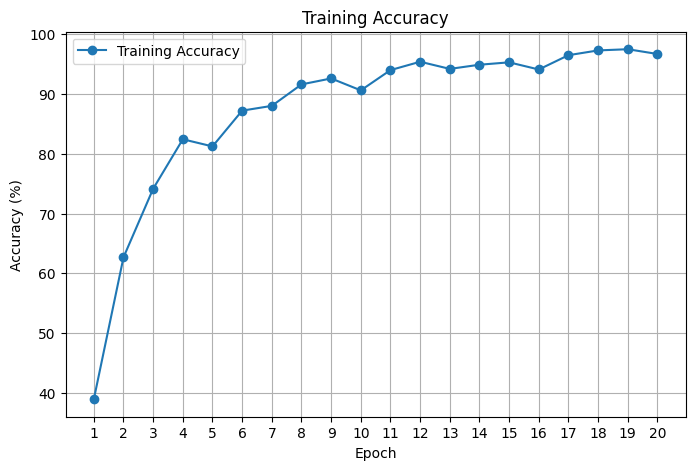

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_accuracies) +1),
    train_accuracies,
    label='Training Accuracy',
    marker='o'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training Accuracy')

plt.legend()
plt.grid(True)
plt.xticks(range(1, len(train_accuracies) +1))
plt.show()

In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 92.09%
